# Phần của Bảo – IS403.R13 Nhóm 4
**Nội dung:** B3 tiền xử lý (H, age_b, lv_adj, viral_A, bộ 6 số) · B4 Q1 thống kê mô tả · B5 Q3b hồi quy Logistic · B6 bảng độ tin cậy.

Notebook này gọi lại các script trong `python/` nên số liệu luôn khớp với file `.py`. **Đổi `DATA_DIR` ở ô đầu tiên sang `data_final_20261113` rồi chạy lại từ đầu (Kernel → Restart & Run All) khi có dữ liệu chốt.**

In [1]:
import os, sys
sys.path.insert(0, os.path.join(os.getcwd(), 'python'))
os.environ['DATA_DIR'] = '/mnt/user-data/uploads'   # <-- ĐỔI SANG data_final_20261113 ở việc B9
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option('display.width', 200, 'display.max_columns', 30, 'display.float_format', lambda x: f'{x:,.4f}')
import prep
master = prep.load_master(); H = prep.prep(master)
print(prep.DATA_DIR, '| videos_master:', len(master), '| H:', len(H))

/mnt/user-data/uploads | videos_master: 96334 | H: 95319


## 1. Bộ 6 số kiểm tra (B3) – điền vào sheet `so_kiem_tra`

In [2]:
for k, v in prep.six_numbers(H).items(): print(k, '->', v)
print(f"viral_A chiếm {100*H.viral_A.mean():.2f}% H (yêu cầu 9–11%)")

1. n_H (số video trong H) -> 95319
2. Số kênh khác nhau trong H -> 328
3. Số video H thuộc nhóm tuổi [7, 10) -> 1594
4. Tổng viral_A (số video dương) -> 9542
5. Trung vị lv_adj trên H (4 chữ số) -> 0.0905
6. Số video H có ever_trending = TRUE -> 399
viral_A chiếm 10.01% H (yêu cầu 9–11%)


## 2. Q1 – Thống kê mô tả (B4)

In [3]:
import q1_descriptive as q1
q1.main()

DATA_DIR=/mnt/user-data/uploads | n_H=95,319 | kênh trong H=328


n_H                                               95319
n_channels_H                                        328
hour_best                                            17
hour_best_val                                    0.5279
hour_worst                                           14
hour_worst_val                                  -0.4331
hour_range                                       0.9610
hour_range_within_channel                        0.1798
dow_range_within_channel                         0.0179
between_channel_var_share                        0.7014
dow_range                                        0.0636
cells_total                                         168
cells_blank                                           0
cell_best                       4h Thứ Tư (1.176, n=80)
cell_worst                   14h Thứ Ba (-0.511, n=372)
cat_best                                         Gaming
cat_worst                                     Education
cat_range_top10                                 

In [4]:
ta = pd.read_csv('outputs/q1/q1_descriptive_table.csv'); ta

,nhom,bien,n,mean,median,sd,cv,skew,kurtosis_excess
0,Tất cả,Lượt xem (gốc),95319,"353,577.7386","29,337.0000","2,949,896.9546",8.3430,41.6812,"2,424.5071"
1,Tất cả,Lượt xem (log10),95319,4.3808,4.4674,1.1208,0.2558,-0.3827,0.2958
2,Tất cả,Lượt thích (gốc),92777,"5,898.6596",294.0000,"45,847.1179",7.7725,28.3178,"1,260.1593"
3,Tất cả,Lượt thích (log10),89674,2.4620,2.5172,1.1080,0.4501,-0.0002,-0.3409
4,Tất cả,Bình luận (gốc),93279,248.8814,10.0000,"3,137.4446",12.6062,42.9049,"2,443.3412"
5,Tất cả,Bình luận (log10),71719,1.4176,1.3802,0.8724,0.6155,0.3542,-0.1680
6,Video ngắn (<=60s),Lượt xem (gốc),19847,"450,402.2655","24,535.0000","1,819,780.1863",4.0403,12.2406,233.9037
7,Video ngắn (<=60s),Lượt xem (log10),19847,4.3224,4.3898,1.2639,0.2924,-0.2658,0.0834
8,Video ngắn (<=60s),Lượt thích (gốc),19571,"12,187.2630",311.0000,"53,656.4300",4.4027,11.6184,216.4415
9,Video ngắn (<=60s),Lượt thích (log10),18812,2.5593,2.5587,1.2937,0.5055,0.1411,-0.6727


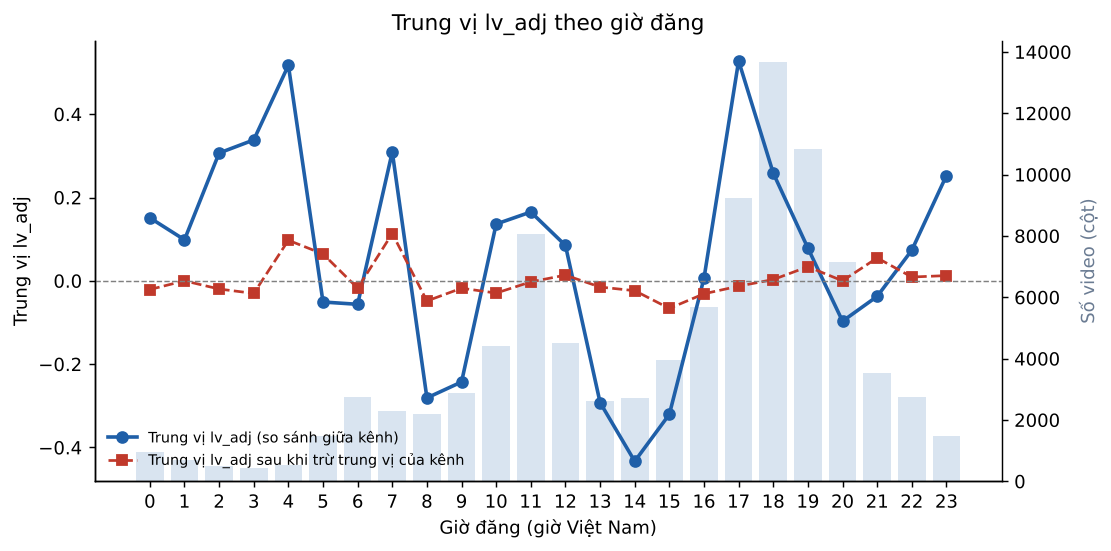

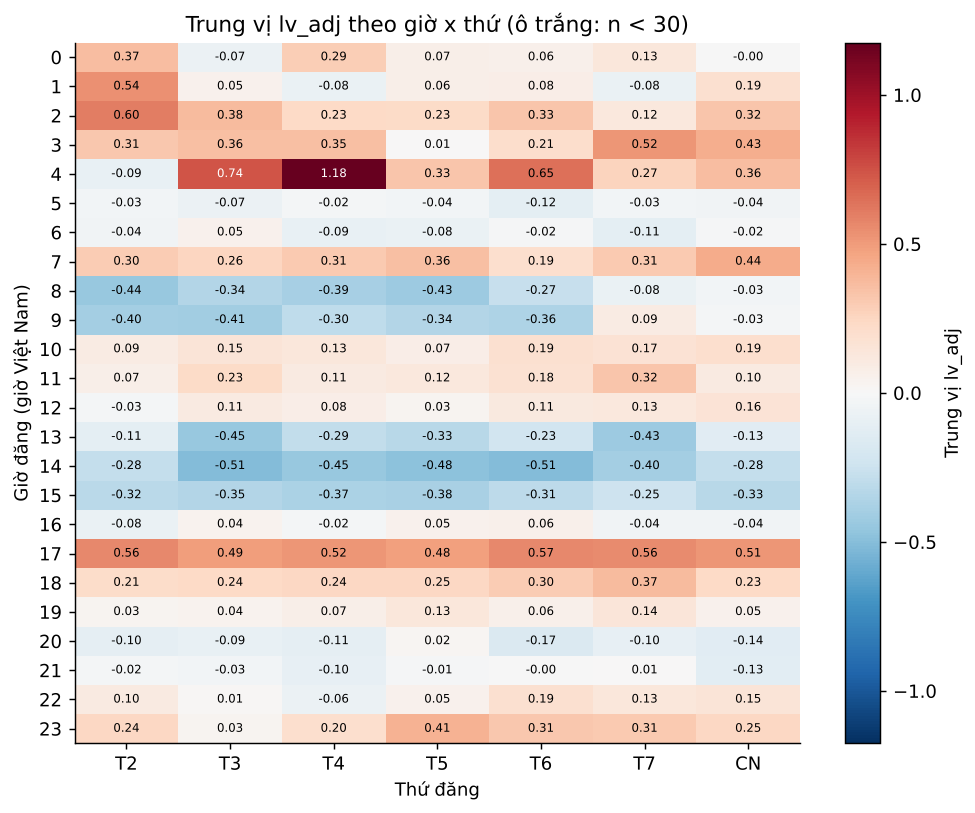

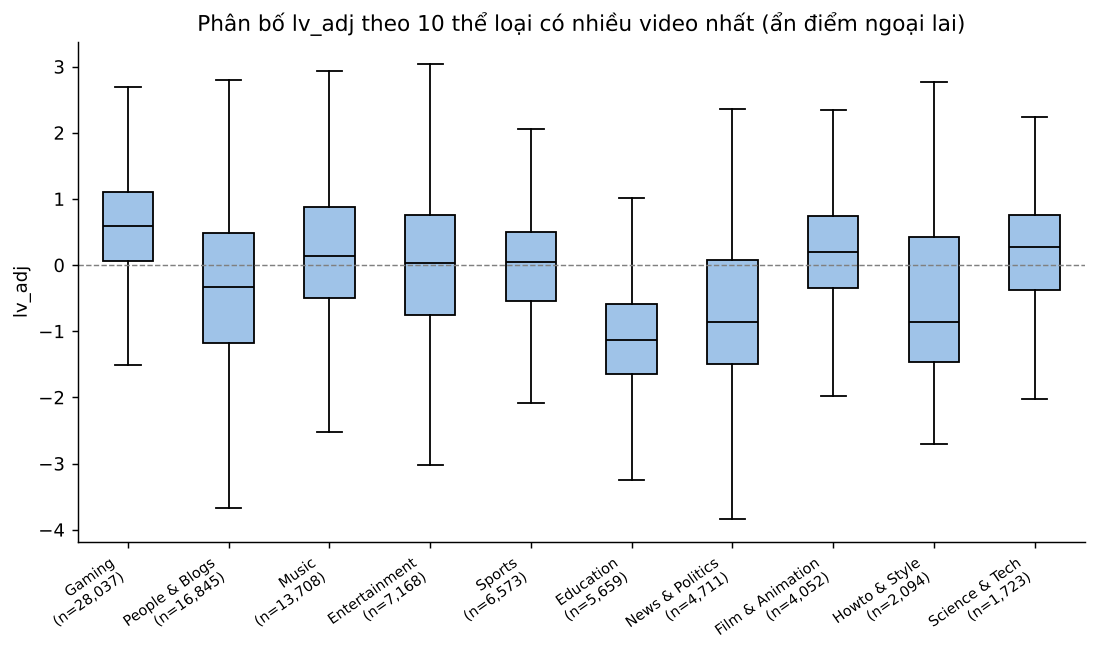

In [5]:
for f in ['q1_by_hour.png','q1_heatmap.png','q1_box_category.png']:
    display(Image('outputs/q1/'+f))

**Đọc kết quả:** chênh lệch trung vị lv_adj theo giờ (thô) lớn hơn rất nhiều so với chênh lệch sau khi trừ trung vị của chính kênh → phần lớn là hiệu ứng *kênh nào đăng giờ nào*, không phải hiệu ứng giờ đăng.

In [6]:
pd.read_csv('outputs/q1/q1_by_hour.csv')[['pub_hour','n','median_lv_adj','median_lv_within_channel','median_like_rate']]

,pub_hour,n,median_lv_adj,median_lv_within_channel,median_like_rate
0,0,967,0.1513,-0.0208,0.0138
1,1,697,0.0985,0.0000,0.0148
2,2,493,0.3067,-0.0197,0.0129
3,3,430,0.3382,-0.0301,0.0121
4,4,521,0.5172,0.0973,0.0086
5,5,1474,-0.0508,0.0645,0.0148
6,6,2746,-0.0563,-0.0176,0.0087
7,7,2277,0.3093,0.1136,0.0065
8,8,2184,-0.2810,-0.0484,0.0084
9,9,2885,-0.2427,-0.0177,0.0088


## 3. Q3b – Hồi quy Logistic cho viral_A (B5)

In [7]:
import q3b_logistic as q3
q3.main()

DATA_DIR=/mnt/user-data/uploads | n_H=95,319 | viral_A dương=9,542


Thông tin thiết kế: {'n_dropped_missing': 0, 'n_removed_small_category': 1, 'cat_reference': 'Gaming', 'cat_small_merged_or_removed': ['Nonprofits & Activism']} | n dùng: 95318 | số cụm kênh: 328



=== Độ phù hợp ===
                       model     n  n_pos  pct_pos  n_clusters  k_params       loglik  loglik_null         AIC         BIC  McFadden_R2  converged    LR_vs_M1
               M1 (đủ biến) 95318   9541  10.0097         328        34 -22,415.8295 -31,006.4684 44,899.6590 45,221.4681       0.2771       True         NaN
     M2 (bỏ nhóm biến kênh) 95318   9541  10.0097         328        31 -27,833.4507 -31,006.4684 55,728.9014 56,022.3156       0.1023       True 10,835.2424
M3 (pub_slot thay pub_hour) 95318   9541  10.0097         328        37 -22,389.2784 -31,006.4684 44,852.5568 45,202.7608       0.2779       True         NaN

=== OR M1 / M2 ===
                            label   OR_M1  OR_lo95_M1  OR_hi95_M1   p_M1  OR_M2   p_M2    VIF
                          Hằng số  0.0620      0.0390      0.0970 0.0000 0.1690 0.0000    NaN
              Giờ đăng (pub_hour)  0.9590      0.8640      1.0640 0.4300 1.0130 0.8280 1.0710
               Thứ đăng (pub_dow)  1.0740    

In [8]:
t = pd.read_csv('outputs/q3b/q3b_or_table.csv')
t[['label','OR_M1','OR_lo95_M1','OR_hi95_M1','p_M1','OR_M2','p_M2','VIF']]

,label,OR_M1,OR_lo95_M1,OR_hi95_M1,p_M1,OR_M2,p_M2,VIF
0,Hằng số,0.0615,0.0388,0.0975,0.0000,0.1690,0.0000,NaN
1,Giờ đăng (pub_hour),0.9589,0.8640,1.0642,0.4296,1.0130,0.8276,1.0709
2,Thứ đăng (pub_dow),1.0737,1.0191,1.1312,0.0076,1.0588,0.0161,2.6455
3,Tháng đăng (pub_month),1.1895,1.1233,1.2595,0.0000,1.0906,0.0131,1.0684
4,log10 độ dài video (duration_sec),0.9783,0.7506,1.2749,0.8707,0.9001,0.4363,2.4350
5,Số thẻ tag (tags_count),1.0155,0.8214,1.2555,0.8868,0.9501,0.7001,1.3271
6,Độ dài tiêu đề (title_len),0.9364,0.6486,1.3519,0.7257,1.0009,0.9969,9.4219
7,Số từ tiêu đề (title_words),1.0626,0.7866,1.4353,0.6925,0.7619,0.1552,9.8613
8,Tỷ lệ chữ HOA tiêu đề,0.9932,0.8561,1.1523,0.9284,0.9699,0.7470,1.2392
9,Số hashtag trong tiêu đề,1.0971,0.9272,1.2981,0.2805,1.0233,0.8014,2.0091


,model,n,n_pos,pct_pos,n_clusters,k_params,loglik,loglik_null,AIC,BIC,McFadden_R2,converged,LR_vs_M1
0,M1 (đủ biến),95318,9541,10.0097,328,34,"-22,415.8295","-31,006.4684","44,899.6590","45,221.4681",0.2771,True,NaN
1,M2 (bỏ nhóm biến kênh),95318,9541,10.0097,328,31,"-27,833.4507","-31,006.4684","55,728.9014","56,022.3156",0.1023,True,"10,835.2424"
2,M3 (pub_slot thay pub_hour),95318,9541,10.0097,328,37,"-22,389.2784","-31,006.4684","44,852.5568","45,202.7608",0.2779,True,NaN


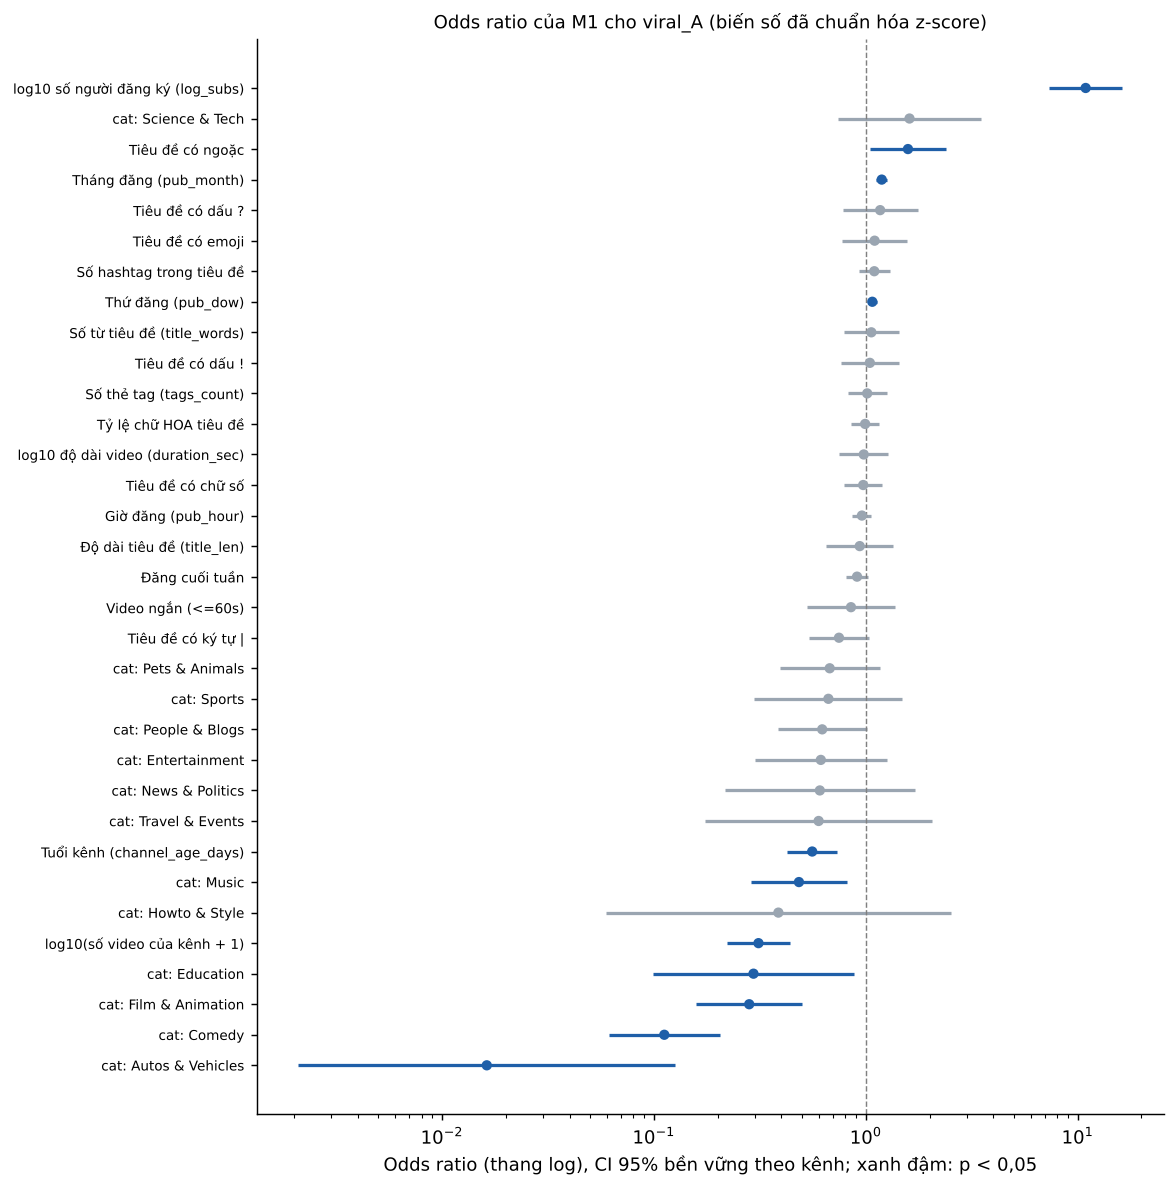

In [9]:
display(pd.read_csv('outputs/q3b/q3b_model_fit.csv')); display(Image('outputs/q3b/q3b_forest_M1.png'))

## 4. Độ tin cậy (a) – bảng chất lượng (B6)

In [10]:
import reliability
reliability.main()

                                                       tieu_chi  so_dem  mau_so  ty_le_pct
                                   Ẩn lượt thích (likes_hidden)    2661   96334     2.7600
                              Tắt bình luận (comments_disabled)    2059   96334     2.1400
                               Độ dài video rỗng (duration_sec)       9   96334     0.0100
             Trùng lặp video (video_id lặp trong videos_master)       0   96334     0.0000
               Trùng lặp lần đo (cùng video_id và collected_ts)       0  216842     0.0000
              Trùng lặp dòng Trending (cùng run_ts và video_id)       0    1967     0.0000
                       Ngoại lai IQR trên log_views (dưới 1.37)     899   96164     0.9300
                       Ngoại lai IQR trên log_views (trên 7.44)     111   96164     0.1200
                         Lượt thích > lượt xem (trước làm sạch)     167  216842     0.0800
                   Lượt thích > lượt xem (còn lại sau làm sạch)       0  216842     0.0000

In [11]:
pd.read_csv('outputs/reliability/reliability_table.csv')

,tieu_chi,so_dem,mau_so,ty_le_pct,cach_xu_ly,nguon_tinh
0,Ẩn lượt thích (likes_hidden),2661,96334,2.7600,"Giữ video; likes và like_rate để NaN, chỉ tính tỷ lệ trên video có...",videos_master.csv
1,Tắt bình luận (comments_disabled),2059,96334,2.1400,Giữ video; comments và comment_rate để NaN,videos_master.csv
2,Độ dài video rỗng (duration_sec),9,96334,0.0100,Giữ trong thống kê chung; loại khỏi mô hình dùng duration,videos_master.csv
3,Trùng lặp video (video_id lặp trong videos_master),0,96334,0.0000,Loại khi làm sạch; kiểm tra lại trên file sạch phải bằng 0,videos_master.csv
4,Trùng lặp lần đo (cùng video_id và collected_ts),0,216842,0.0000,Loại khi làm sạch; kiểm tra lại trên file sạch phải bằng 0,measurements.csv
5,Trùng lặp dòng Trending (cùng run_ts và video_id),0,1967,0.0000,Kiểm tra trên file sạch,trending_clean.csv
6,Ngoại lai IQR trên log_views (dưới 1.37),899,96164,0.9300,GIỮ (không loại): đây là video thật có ít lượt xem; phân tích dùng...,videos_master.csv
7,Ngoại lai IQR trên log_views (trên 7.44),111,96164,0.1200,GIỮ (không loại): video có lượt xem rất cao là hiện tượng thật của...,videos_master.csv
8,Lượt thích > lượt xem (trước làm sạch),167,216842,0.0800,Đặt likes = NaN (nhiễu API / video mới),dq_report.txt
9,Lượt thích > lượt xem (còn lại sau làm sạch),0,216842,0.0000,Phải bằng 0,measurements.csv
